In [15]:
import sys
sys.path.append('/data/user/wu_j1/bamf')

In [16]:
import pandas as pd
import h5py
import numpy as np
from analysis_codes.analysis import *
from analysis_codes.plotting import *
from tqdm import tqdm

# Common parameters

In [17]:
components = 5
result_path="/data/user/wu_j1/comparison/"
cutoff=5
outfilename = "ZH_mz115.zip"

In [18]:
filename_pmf = "ZH_march_mz115"
folder_pmf = "/data/user/wu_j1/PMF_results/mz115/"
reference_file_pmf = "/data/user/wu_j1/Zurich-ToF-ACSM/mz115/processed/input_matrices_martavia_noised_20220315_winter.h5"
benchmark=True

result_pmf = folder_pmf + "ME2_results/" + filename_pmf + ".h5"


In [19]:
folder_bamf = "/data/user/wu_j1/bamf/run_job/"
filename_bamf = "mz115/results/march_mz115.h5"
match_file="datafile"

result_bamf = folder_bamf + filename_bamf

# PMF results

In [20]:
with h5py.File(result_pmf, "r") as f:
    # List all groups
    print("Keys: %s" % f.keys())
    print("Keys: %s" % f["PMF_input"].keys())

Keys: <KeysViewHDF5 ['PMF_input', 'run_0', 'run_1', 'run_2', 'run_3', 'run_4', 'run_5', 'run_6', 'run_7']>
Keys: <KeysViewHDF5 ['Mx_data_str', 'Mx_data_unit', 'Mx_err_str', 'Specs', 'amus_nb', 'amus_nb_txt', 'batch_file', 'cons_steps', 'deltaQ', 'errors', 'gg2_steps', 'iteration_eff', 'logfile_notebook', 'max_steps', 'model_txt_factor_specs', 'pr_class_color', 'pr_class_color_ov', 'pr_class_name', 'pr_class_name_ov', 'profile_index', 'solution_para', 'timelist', 'ts_class_color', 'ts_class_color_ov', 'ts_class_name', 'ts_class_name_ov', 'tseries_class_str', 'tseries_index', 'tseries_nb_str', 'variable_nb_str', 'variable_txt_str']>


In [21]:
frame,netcdf_pmf= analyze_frame_for_pmf(
    result_pmf,
    reference_file_pmf,
    components,
    str(components) + " component benchmark",
     benchmark = benchmark,
    #mz115
    dataname="Specs",
    errorname="errors",
    prname="amus_nb",
    tsname="timelist",
    cutoff=cutoff,
    force_normalization=True,
    add_mz_mode=True,
)

Sorting sample sizes: (3, 5, 82) (3, 1416, 5)


100%|████████████████████████████████████████████| 3/3 [00:00<00:00, 134.50it/s]

There are 3 possible orderings
Each ordering has appeared: [1 1 1]
Sorting
adding few mzs...


Identified components: [(0, 'A_DEC_W_035_BBOA_t'), (1, 'A_DEC_W_037_HOA_t'), (2, 'SOAbb_t'), (3, 'SOAbio_t'), (4, 'SOAtraffic_t')]
A_DEC_W_035_BBOA_t statistics
A_DEC_W_037_HOA_t statistics
SOAbb_t statistics
SOAbio_t statistics
SOAtraffic_t statistics


# BAMF results

In [23]:


runfile = pd.read_hdf(result_bamf, "runs")

complete = runfile[runfile["status"] == "finished"]

diagnostics = {"start", "stop", "duration", "filename", "status", "result", "seed"}
groupers = [h for h in complete.columns if h not in diagnostics]
gb = complete.groupby(groupers)



basepath=Path(result_path)
distance_metric="cityblock"



rows = []
sorted_data_bamf_ls = []
output_ls = []
for group in gb:

    full_row = {g: v for g, v in zip(groupers, group[0])}
    frame = group[1]
    output, sorted_data_bamf, metrics = analyze_frame_wo_plot(
            frame,
            benchmark=benchmark,
            basepath=basepath,
            distance_metric=distance_metric,
            match_file=match_file,
            cutoff=cutoff,
            add_mz_mode = True
        )

    full_row.update(metrics)

    rows.append(full_row)
    sorted_data_bamf_ls.append(sorted_data_bamf)
    output_ls.append(output)

X The files have matching variables.
m The files have matching variables.
n The files have matching variables.
p The files have matching variables.
sigma The files have matching variables.
norm_const The files have matching variables.
Sorting sample sizes: (2, 5, 82) (2, 1416, 5)


100%|██████████████████████████████████████| 2000/2000 [00:10<00:00, 195.66it/s]

There are 2 possible orderings
Each ordering has appeared: [1 1]
Sorting


dict_keys(['F', 'G', 'X', 'm', 'n', 'p', 'lp__', 'sigma', 'norm_const', 'alpha_a', 'alpha_b', 'chains', 'samples', 'Z', 'timestep', 'variable', 'F_orig', 'G_orig'])
/data/user/wu_j1/comparison/5_basic_datafile-input_matrices_martavia_noised_20220315_winter.zip
median solution
descriptive
z-data
Q statistics
Z statistics
Alpha statistics
alpha_a mean
alpha_a median
alpha_a std
alpha_b mean
alpha_b median
alpha_b std
A_DEC_W_035_BBOA_t statistics
A_DEC_W_037_HOA_t statistics
SOAbb_t statistics
SOAbio_t statistics
SOAtraffic_t statistics
adding few mzs...


In [24]:
sorted_data_bamf

<xarray.Dataset>
Dimensions:      (samples: 2000, labels: 5, variable: 86, timestep: 1416, orig_labels: 5)
Coordinates:
  * samples      (samples) int64 0 1 2 3 4 5 6 ... 1994 1995 1996 1997 1998 1999
  * labels       (labels) object 'A_DEC_W_035_BBOA_t' ... 'SOAtraffic_t'
  * variable     (variable) int64 13 15 16 17 18 25 ... 110 111 112 113 114 115
  * timestep     (timestep) datetime64[ns] 2011-02-01 ... 2011-03-31T23:00:00
  * orig_labels  (orig_labels) object 'A_DEC_W_035_BBOA_t' ... 'SOAtraffic_t'
Data variables:
    F            (samples, labels, variable) float64 4.034e-06 ... 0.01021
    G            (samples, timestep, labels) float64 2.458 0.8849 ... 0.1026
    X            (timestep, variable) float64 0.04137 0.2691 ... 0.01797
    error        (timestep, variable) float64 0.0008375 0.00184 ... 0.0002631
    F_orig       (orig_labels, variable) float64 0.009322 0.0684 ... 0.008837
    G_orig       (timestep, orig_labels) float64 3.15 1.677 ... 2.612 0.172

# Plotting comparison

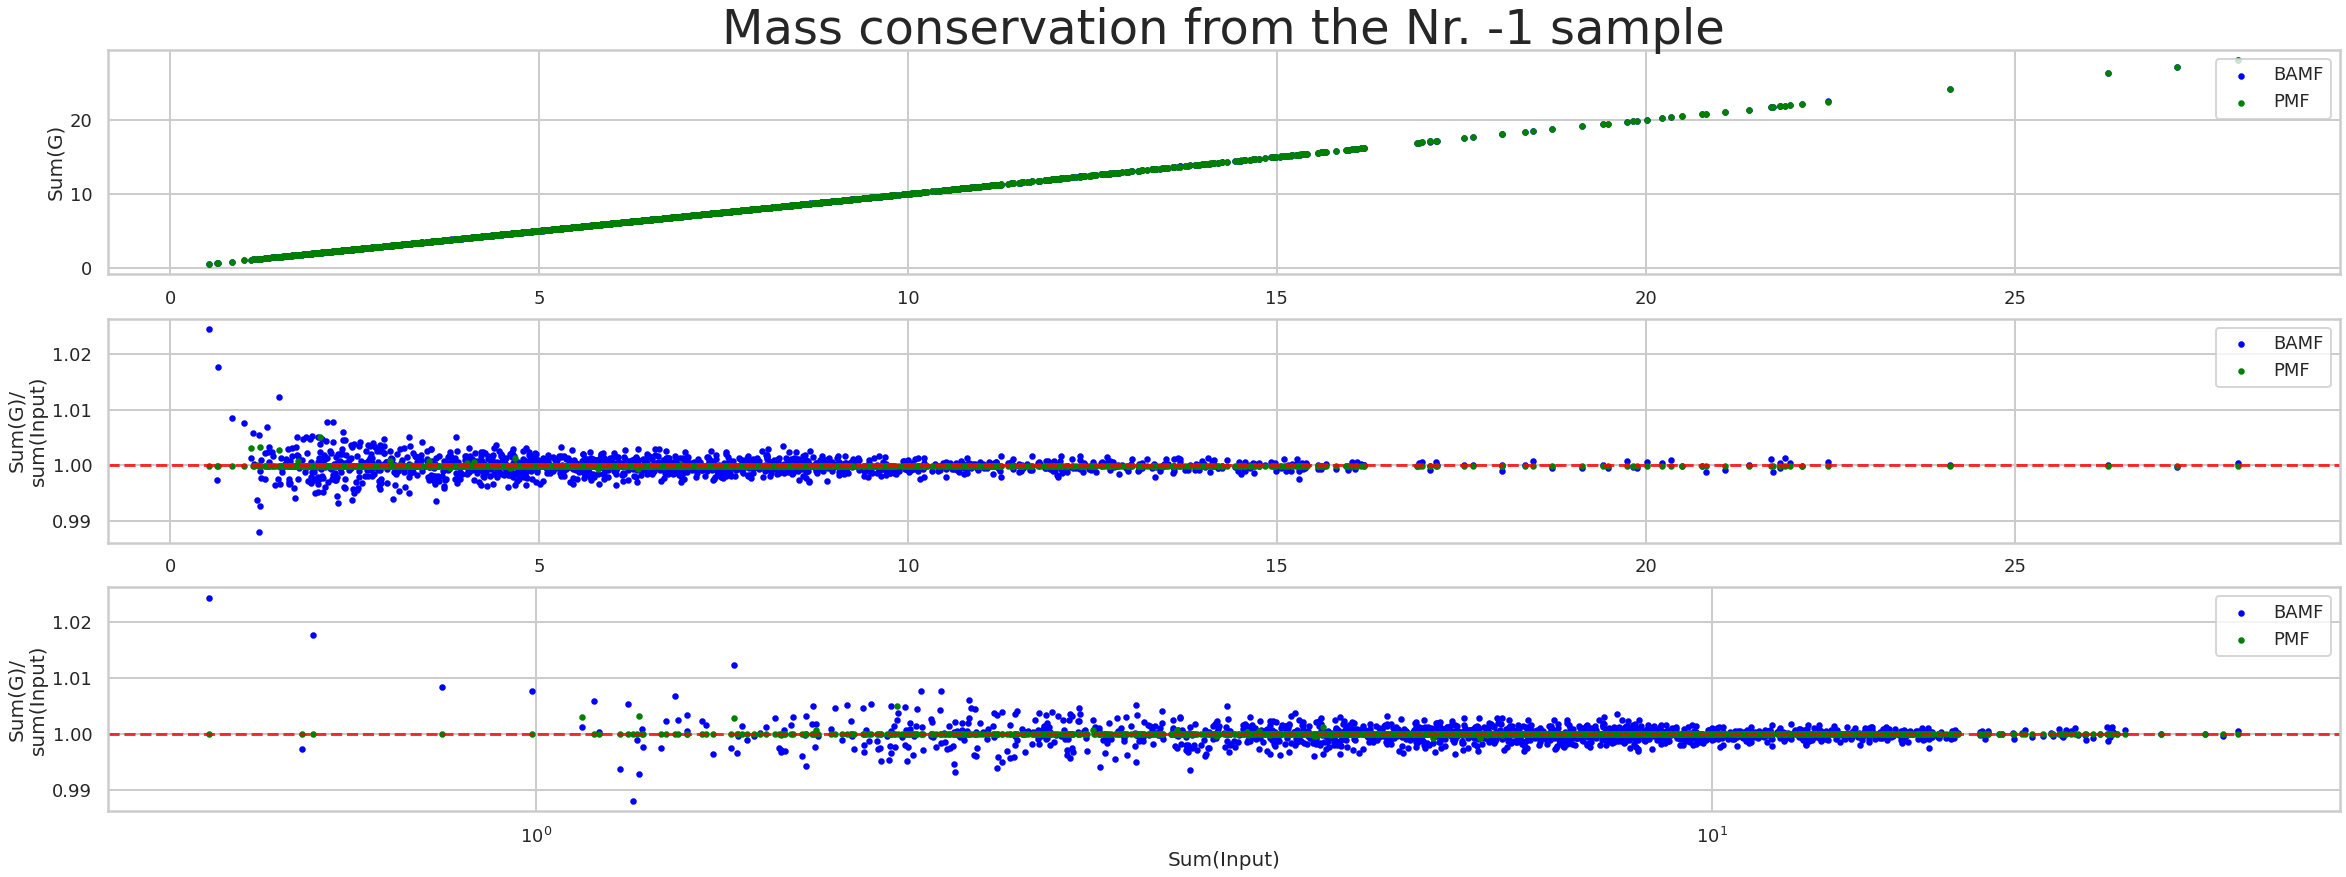

In [28]:
f_mass_last = mass_conservation_comparison(sorted_data_bamf,netcdf_pmf,-1)

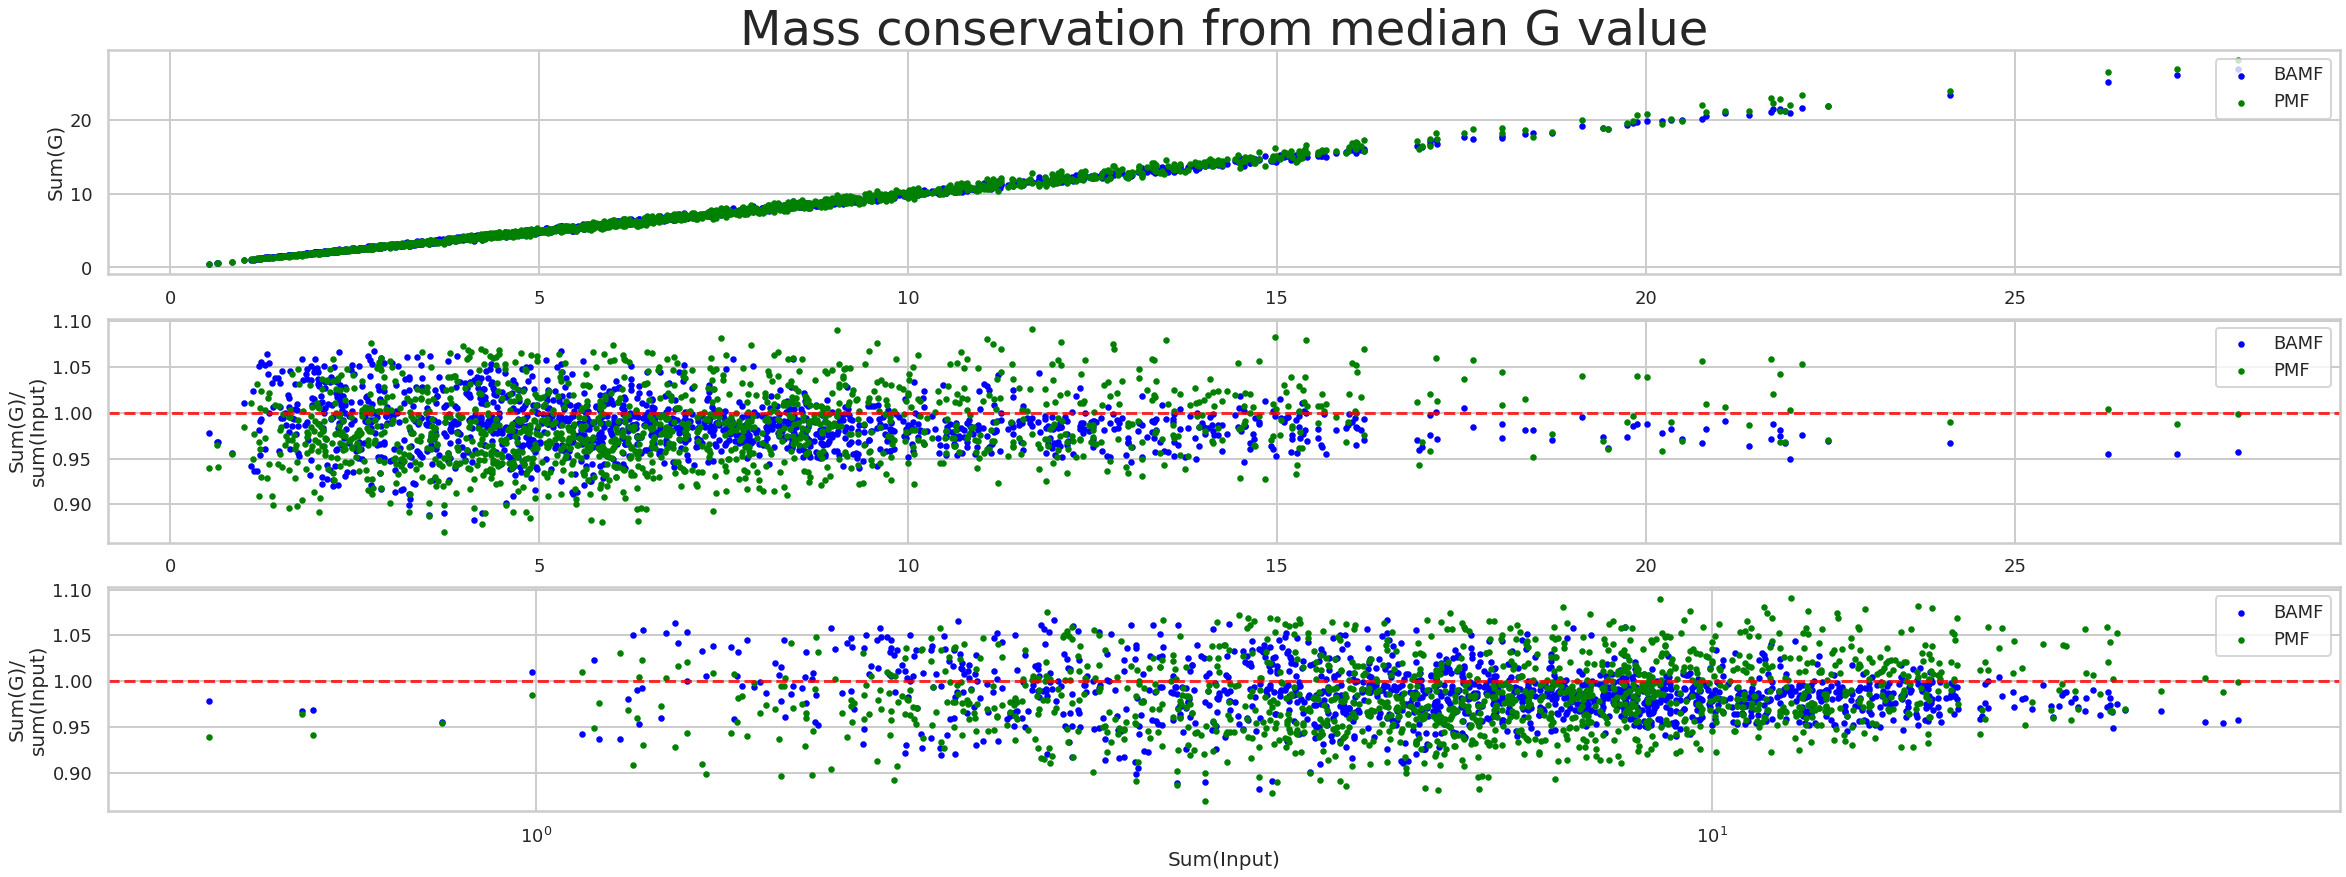

In [29]:
f_mass_median = mass_conservation_comparison(sorted_data_bamf,netcdf_pmf,"median")

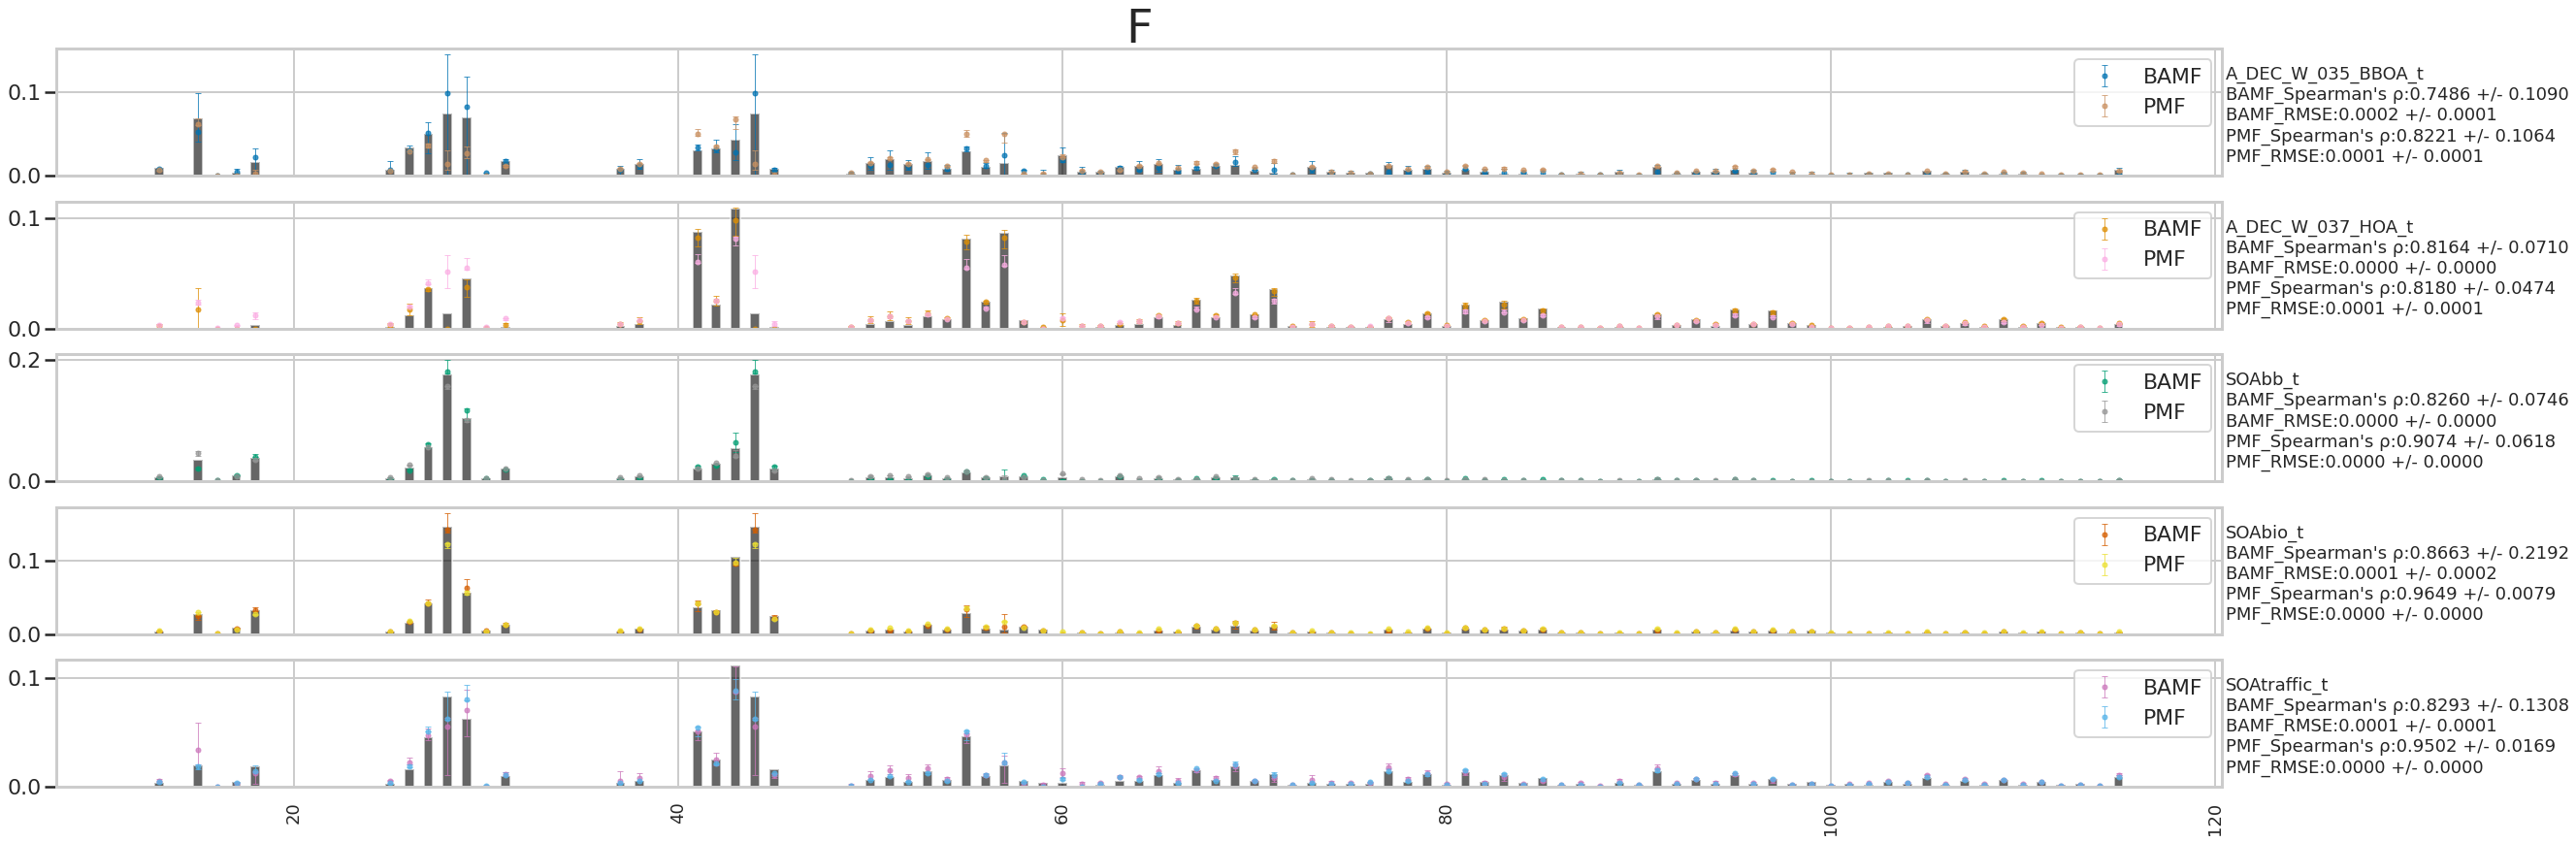

In [30]:
F = plot_F_comparison(sorted_data_bamf,netcdf_pmf,benchmark=benchmark)

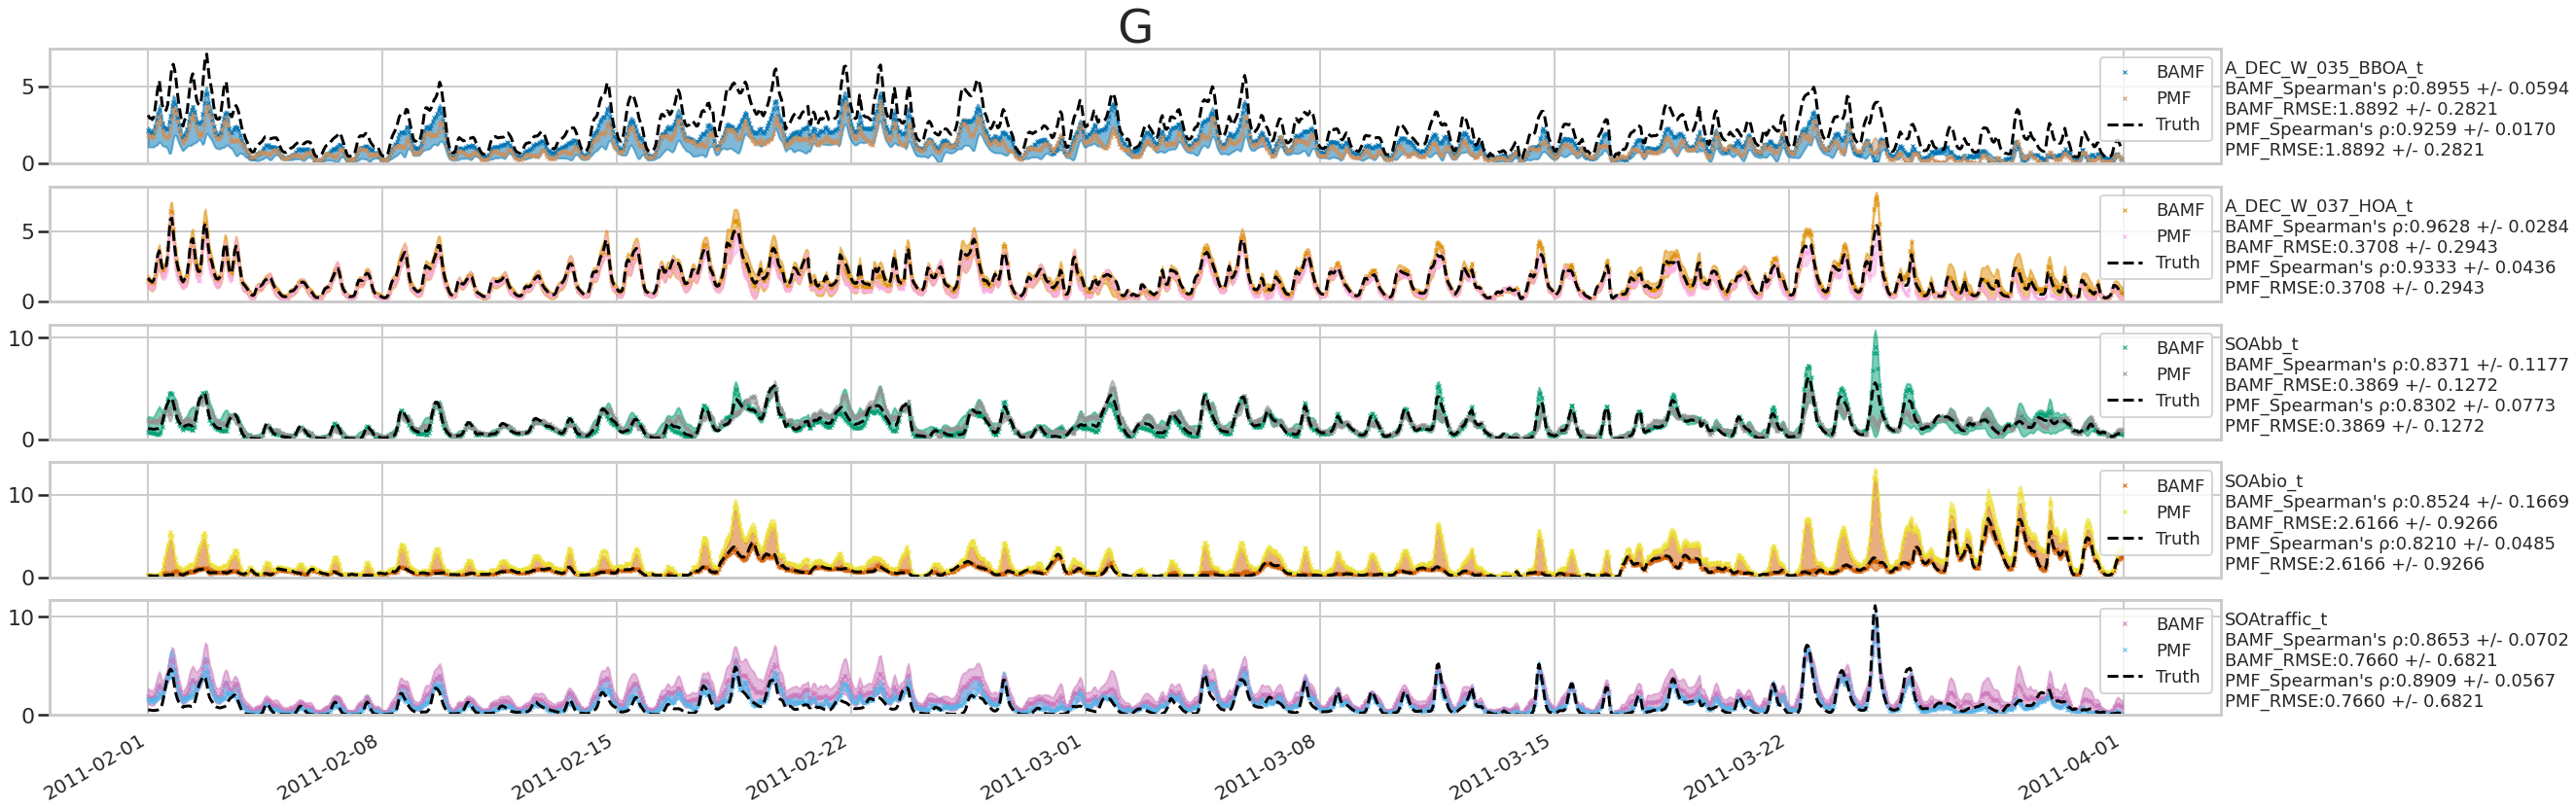

In [31]:
G = plot_G_comparison(sorted_data_bamf,netcdf_pmf,benchmark=benchmark)

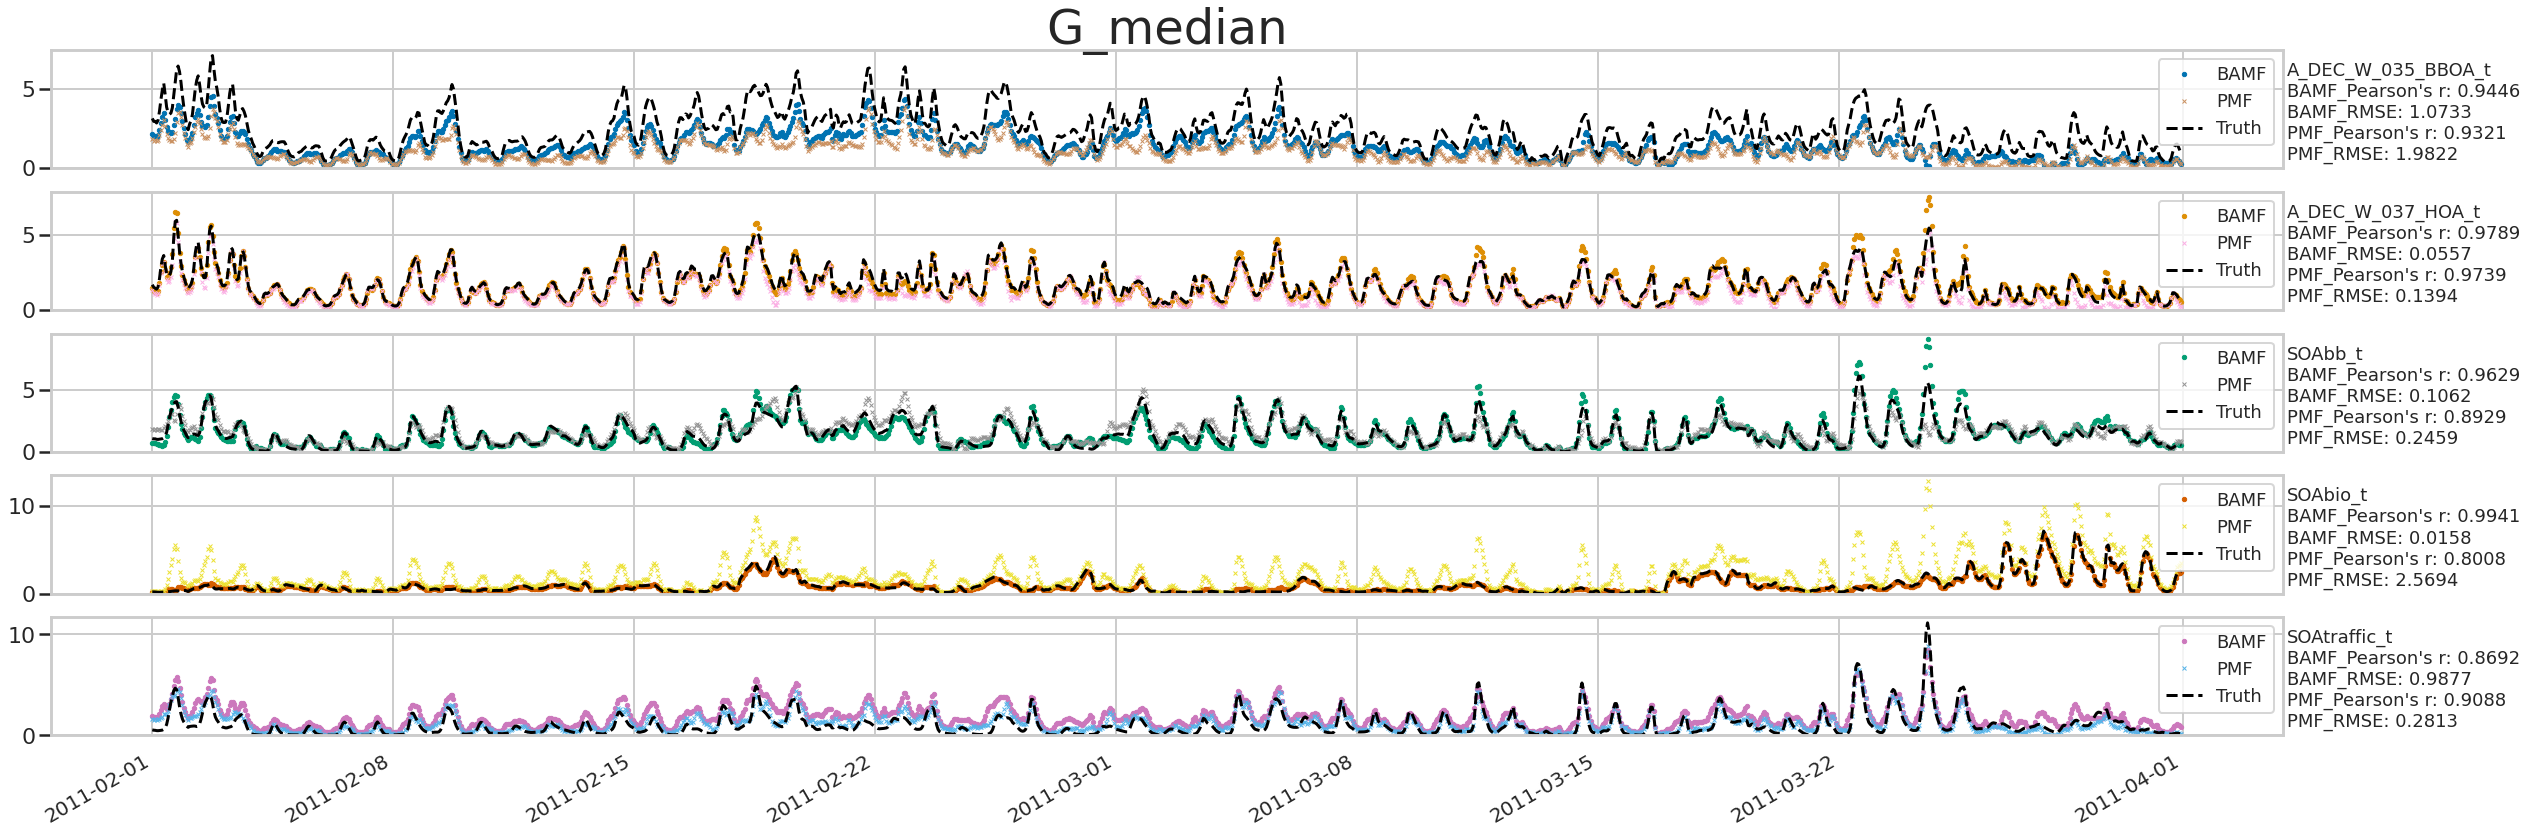

In [32]:
G_median= plot_median_G_comparison(sorted_data_bamf,netcdf_pmf,benchmark=benchmark)

# Save plots

In [49]:

Path(result_path + outfilename).parent.mkdir(parents=True, exist_ok=True)
with Collated_output(output) as outfile:
    outfile.savefig(f_mass_last, "conservation from last sample")
    outfile.savefig(f_mass_median, "conservation from median G")
    outfile.savefig(F, "F")
    outfile.savefig(G, "G")
    outfile.savefig(G_median, "G_median")